# 01 Data: download, checks and split

**Owners:** both. **Runs in:** a few seconds once the archive is downloaded (330 MB).

What this notebook shows:
1. The three official files are downloaded and checked against published MD5 checksums.
2. The supplied split is kept: train 1,020, validation 1,020, test 6,149. Train and validation together form the **selection set** (settings are chosen there, without labels). Test is used once, at the end.
3. How unbalanced the species are, and what the images look like after our shared preprocessing.

Species labels are *not* loaded here. Only per-species counts are shown, which describe the dataset and say nothing about which image is which species.

In [8]:
%pip install joblib matplotlib numpy pandas pillow scikit-image scikit-learn scipy torch torchvision ipykernel

Note: you may need to restart the kernel to use updated packages.


In [9]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from p22 import config, data
pd.set_option("display.precision", 3)

## 1. Download and verify
`data.download()` skips files that already exist, then checks every MD5 and the image count.

In [10]:
data.download()
split = data.load_split()
{name: len(idx) for name, idx in split.items()}

102flowers.tgz: md5 ok
imagelabels.mat: md5 ok
setid.mat: md5 ok


{'train': 1020, 'val': 1020, 'test': 6149, 'selection': 2040}

## 2. The split is complete and has no overlap

In [11]:
all_idx = np.concatenate([split["train"], split["val"], split["test"]])
assert len(all_idx) == len(np.unique(all_idx)) == config.N_IMAGES
print("every image is in exactly one split")

every image is in exactly one split


## 3. Images per species
The classes are unbalanced (40 to 258 images). This is why we report the *adjusted* Rand index, which corrects for chance, and why large species can dominate clusters.

min 40, median 66, max 258


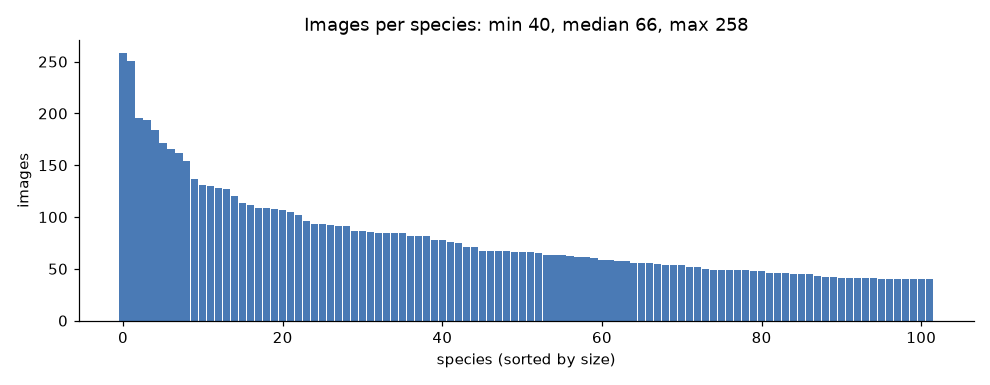

In [12]:
counts = data.class_counts()
print(f"min {counts.min()}, median {np.median(counts):.0f}, max {counts.max()}")
display(Image(config.FIGURES_DIR / "data_class_counts.png"))

## 4. Shared preprocessing
Shorter side resized to 256 px, then the central 224x224 crop. Both representations see exactly these pixels (DECISIONS.md, D2).

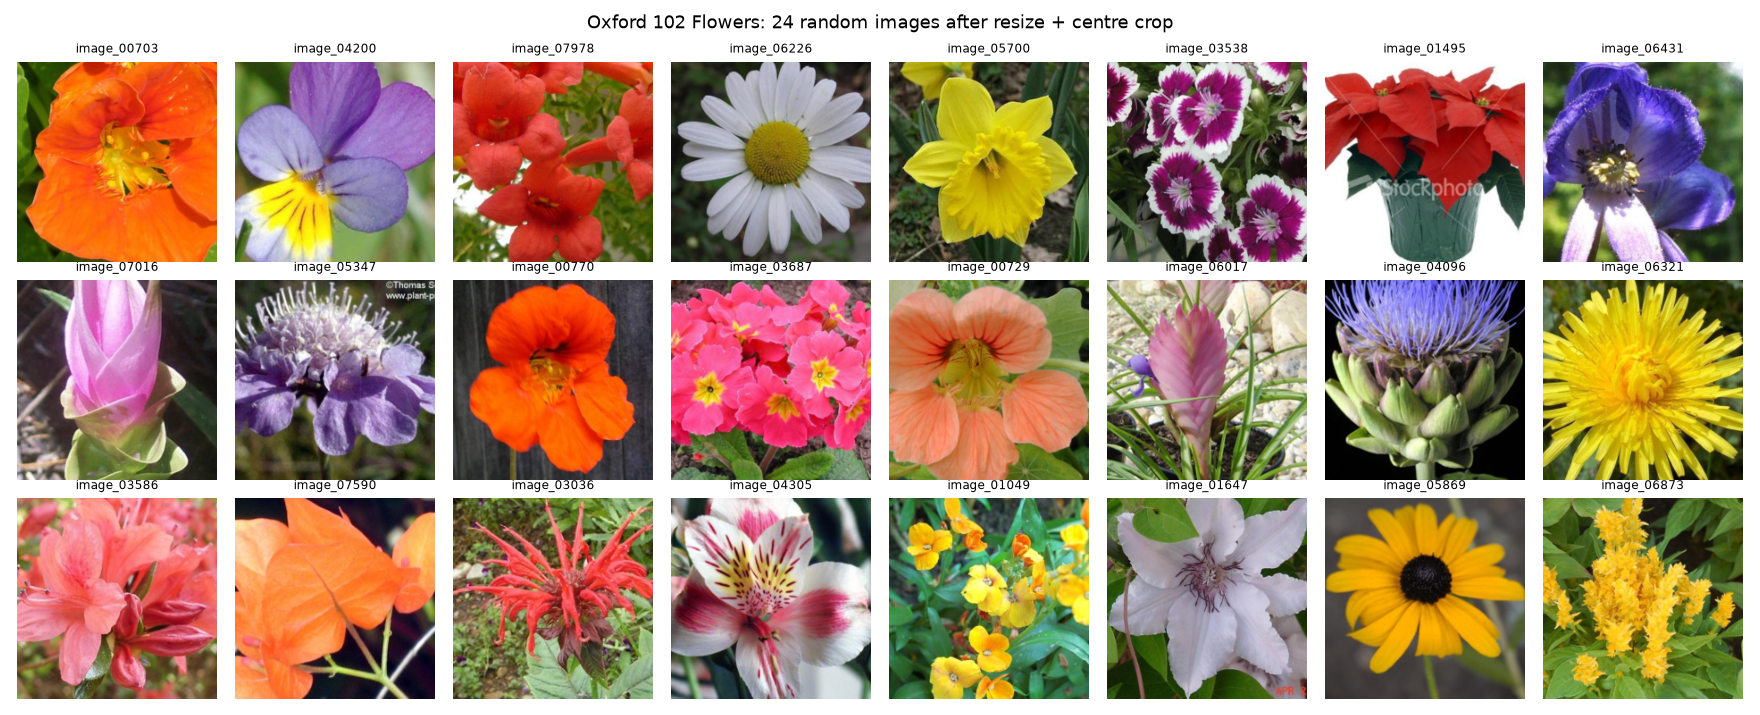

In [13]:
display(Image(config.FIGURES_DIR / "data_sample_grid.png"))

The full file list with each image's split and SHA-256 is in `results/manifest.tsv` (made by `scripts/download_data.py`). It lets anyone check they have the same data without us redistributing the images.

## Check your setup

Before moving to notebook 02, make sure that:
1. The data is downloaded and the split loaded correctly (train 1,020, validation 1,020, test 6,149).
2. Every image is in the correct split.
3. The class counts are shown (8,189 images, 102 species).
4. The sample grid of images is displayed.

If the images or charts don't show, run the required script first, from the repo root:
`python scripts/plot_data_overview.py`
This creates `figures/data_class_counts.png` and `figures/data_sample_grid.png`. Then re-run the cells above.